In [8]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://api.openf1.org/v1/sessions"

params = {
    "year": 2024,
    "session_name": "Race"
}

response = requests.get(url, params=params, timeout=30)

response.raise_for_status()

sessions = pd.DataFrame(response.json())

print(sessions[['session_key', 'location', 'session_name']])

    session_key           location session_name
0          9472             Sakhir         Race
1          9480             Jeddah         Race
2          9488          Melbourne         Race
3          9496             Suzuka         Race
4          9673           Shanghai         Race
5          9507              Miami         Race
6          9515              Imola         Race
7          9523             Monaco         Race
8          9531           Montréal         Race
9          9539          Barcelona         Race
10         9550          Spielberg         Race
11         9558        Silverstone         Race
12         9566           Budapest         Race
13         9574  Spa-Francorchamps         Race
14         9582          Zandvoort         Race
15         9590              Monza         Race
16         9598               Baku         Race
17         9606         Marina Bay         Race
18         9617             Austin         Race
19         9625        Mexico City      

In [9]:
abu_dhabi = sessions[
    sessions['location'].str.contains(
        'Abu Dhabi',
        case=False,
        na=False
    )
]

print(abu_dhabi[['session_key', 'location', 'session_name']])

Empty DataFrame
Columns: [session_key, location, session_name]
Index: []


In [10]:
print("Total sessions:", len(sessions))

print("\nAvailable columns:")
print(sessions.columns.tolist())

print("\n2024 race locations:")
print(sessions['location'].unique())

Total sessions: 24

Available columns:
['session_key', 'session_type', 'session_name', 'date_start', 'date_end', 'meeting_key', 'circuit_key', 'circuit_short_name', 'country_key', 'country_code', 'country_name', 'location', 'gmt_offset', 'year', 'is_cancelled']

2024 race locations:
['Sakhir' 'Jeddah' 'Melbourne' 'Suzuka' 'Shanghai' 'Miami' 'Imola'
 'Monaco' 'Montréal' 'Barcelona' 'Spielberg' 'Silverstone' 'Budapest'
 'Spa-Francorchamps' 'Zandvoort' 'Monza' 'Baku' 'Marina Bay' 'Austin'
 'Mexico City' 'São Paulo' 'Las Vegas' 'Lusail' 'Yas Island']


In [11]:
abu_dhabi = sessions[
    sessions['location'] == 'Yas Island'
]

print(
    abu_dhabi[
        ['session_key', 'location', 'country_name', 'session_name']
    ]
)

    session_key    location          country_name session_name
23         9662  Yas Island  United Arab Emirates         Race


In [12]:
session_key = abu_dhabi.iloc[0]['session_key']

print("Abu Dhabi session key:", session_key)

Abu Dhabi session key: 9662


In [13]:
url = "https://api.openf1.org/v1/laps"

params = {
    "session_key": session_key
}

response = requests.get(url, params=params, timeout=30)

response.raise_for_status()

laps = pd.DataFrame(response.json())

print("Total lap records:", len(laps))

laps.head()

Total lap records: 1037


,meeting_key,session_key,driver_number,lap_number,date_start,duration_sector_1,duration_sector_2,duration_sector_3,i1_speed,i2_speed,is_pit_out_lap,lap_duration,segments_sector_1,segments_sector_2,segments_sector_3,st_speed
0,1252,9662,55,1,2024-12-08T13:03:35.033000+00:00,22.217,38.437,32.859,285.0,289.0,False,93.513,"[2048, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2051, 204...","[2049, 2049, 2049, 2051, 2051, 2051, 2049, 204...",298.0
1,1252,9662,1,1,2024-12-08T13:03:35.033000+00:00,25.002,39.931,34.944,290.0,302.0,False,99.877,"[2048, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2051, 2049, 2049, 2049, 2049, 204...",289.0
2,1252,9662,4,1,2024-12-08T13:03:35.033000+00:00,20.498,38.405,32.676,281.0,283.0,False,91.579,"[None, 2049, 2051, 2051, 2049]","[2049, 2051, 2049, 2049, 2049, 2051, 2049, 204...","[2049, 2051, 2049, 2049, 2049, 2049, 2049, 204...",293.0
3,1252,9662,81,1,2024-12-08T13:03:35.033000+00:00,30.241,40.179,33.610,285.0,291.0,False,104.030,"[None, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...",295.0
4,1252,9662,10,1,2024-12-08T13:03:35.033000+00:00,22.656,38.658,33.126,287.0,294.0,False,94.440,"[2048, 2049, 2049, 2049, 2051]","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...","[2051, 2049, 2049, 2049, 2049, 2049, 2049, 204...",306.0


In [14]:
print(laps.columns.to_list())

['meeting_key', 'session_key', 'driver_number', 'lap_number', 'date_start', 'duration_sector_1', 'duration_sector_2', 'duration_sector_3', 'i1_speed', 'i2_speed', 'is_pit_out_lap', 'lap_duration', 'segments_sector_1', 'segments_sector_2', 'segments_sector_3', 'st_speed']


In [15]:
print(laps.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1037 entries, 0 to 1036
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   meeting_key        1037 non-null   int64  
 1   session_key        1037 non-null   int64  
 2   driver_number      1037 non-null   int64  
 3   lap_number         1037 non-null   int64  
 4   date_start         1037 non-null   object 
 5   duration_sector_1  1030 non-null   float64
 6   duration_sector_2  1034 non-null   float64
 7   duration_sector_3  1033 non-null   float64
 8   i1_speed           844 non-null    float64
 9   i2_speed           1034 non-null   float64
 10  is_pit_out_lap     1037 non-null   bool   
 11  lap_duration       1033 non-null   float64
 12  segments_sector_1  1035 non-null   object 
 13  segments_sector_2  1035 non-null   object 
 14  segments_sector_3  1034 non-null   object 
 15  st_speed           1034 non-null   float64
dtypes: bool(1), float64(7), 

In [16]:
missingValues = laps.isna().sum()

print(missingValues[missingValues > 0])

duration_sector_1      7
duration_sector_2      3
duration_sector_3      4
i1_speed             193
i2_speed               3
lap_duration           4
segments_sector_1      2
segments_sector_2      2
segments_sector_3      3
st_speed               3
dtype: int64


In [17]:
print("Total Missing Values: ", laps.isna().sum().sum())

# print("Duplicate Rows: ", laps.duplicated().sum())   Gives error


Total Missing Values:  224


In [18]:
duplicate_laps = laps.duplicated(
    subset=['session_key', 'driver_number', 'lap_number']
)

print("Duplicate laps:", duplicate_laps.sum())


Duplicate laps: 0


In [19]:
race_data = laps.copy()

In [20]:
race_data = race_data.dropna(subset=['lap_duration'])

race_data = race_data[race_data['is_pit_out_lap'] == False].copy()

print("Original Records: ", len(laps))
print("Cleaned Records: ", len(race_data))

Original Records:  1037
Cleaned Records:  1005


In [21]:
race_data['lap_duration'].describe()

count    1005.000000
mean       90.507472
std         4.602013
min        85.637000
25%        88.950000
50%        89.735000
75%        90.268000
max       143.554000
Name: lap_duration, dtype: float64

In [22]:
# Slowest Laps

slowest_laps = race_data.sort_values(
    by= 'lap_duration',
    ascending=False
)

print(
    slowest_laps[
        ['driver_number', 'lap_number', 'lap_duration', 'is_pit_out_lap']
    ].head(10)
)

     driver_number  lap_number  lap_duration  is_pit_out_lap
566             77          30       143.554           False
56              43           3       130.710           False
37              43           2       122.028           False
38              81           2       121.916           False
36              22           2       121.592           False
35              61           2       120.814           False
34              23           2       120.191           False
33              24           2       119.827           False
32              77           2       117.544           False
31              44           2       116.731           False


In [23]:
# Fastest Drivers

fastest_drivers = race_data.sort_values(
    by="lap_duration",
    ascending=True
) 

print(
    fastest_drivers[
        ['driver_number', 'lap_number', 'lap_duration', 'is_pit_out_lap']
    ].head(10)
)

      driver_number  lap_number  lap_duration  is_pit_out_lap
1034             20          57        85.637           False
603              20          32        87.235           False
794              44          44        87.278           False
912              44          51        87.319           False
962              44          54        87.342           False
979              44          55        87.398           False
920               4          52        87.438           False
878              44          49        87.490           False
937               4          53        87.520           False
777              44          43        87.556           False


###Driver Performances

In [24]:
driver_performance = race_data.groupby(
    'driver_number'
)["lap_duration"].agg(
    ['mean', 'min', 'max', 'std', 'count']
).round(3)

driver_performance = driver_performance.sort_values(
    by='mean'
)

driver_performance

,mean,min,max,std,count
driver_number,,,,,
4,89.232,87.438,108.349,3.332,57
55,89.335,87.765,109.770,3.439,57
16,89.771,88.018,113.013,3.719,57
44,89.849,87.278,116.731,4.245,57
63,89.868,88.195,109.838,3.430,57
1,89.895,87.765,114.938,3.959,57
81,90.108,87.690,121.916,4.916,56
14,90.261,87.948,110.156,3.485,56
10,90.465,89.212,109.760,3.216,57


In [25]:
url = "https://api.openf1.org/v1/drivers"

params = {
    "session_key": session_key
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

drivers = pd.DataFrame(response.json())

print(
    drivers[
        ['driver_number', 'full_name', 'team_name']
    ].drop_duplicates()
)

    driver_number         full_name        team_name
0               1    Max VERSTAPPEN  Red Bull Racing
1               4      Lando NORRIS          McLaren
2              10      Pierre GASLY           Alpine
3              11      Sergio PEREZ  Red Bull Racing
4              14   Fernando ALONSO     Aston Martin
5              16   Charles LECLERC          Ferrari
6              18      Lance STROLL     Aston Martin
7              20   Kevin MAGNUSSEN     Haas F1 Team
8              22      Yuki TSUNODA               RB
9              23   Alexander ALBON         Williams
10             24       ZHOU Guanyu      Kick Sauber
11             27   Nico HULKENBERG     Haas F1 Team
12             30       Liam LAWSON               RB
13             43  Franco COLAPINTO         Williams
14             44    Lewis HAMILTON         Mercedes
15             55      Carlos SAINZ          Ferrari
16             61       Jack DOOHAN           Alpine
17             63    George RUSSELL         Me

###Merging Drivers with Driver Performances

In [26]:
driver_performance = driver_performance.reset_index()

driver_performance = driver_performance.merge(
    drivers[['driver_number', 'full_name', 'team_name']].drop_duplicates(subset=['driver_number']),
    on="driver_number",
    how='left'
)

driver_performance = driver_performance.sort_values(
    by='mean'
)

print(
    driver_performance[
        ['driver_number', 'full_name', 'team_name', 'mean', 'min', 'max', 'std', 'count']
    ].round(3)
)


    driver_number         full_name        team_name    mean     min      max  \
0               4      Lando NORRIS          McLaren  89.232  87.438  108.349   
1              55      Carlos SAINZ          Ferrari  89.335  87.765  109.770   
2              16   Charles LECLERC          Ferrari  89.771  88.018  113.013   
3              44    Lewis HAMILTON         Mercedes  89.849  87.278  116.731   
4              63    George RUSSELL         Mercedes  89.868  88.195  109.838   
5               1    Max VERSTAPPEN  Red Bull Racing  89.895  87.765  114.938   
6              81     Oscar PIASTRI          McLaren  90.108  87.690  121.916   
7              14   Fernando ALONSO     Aston Martin  90.261  87.948  110.156   
8              10      Pierre GASLY           Alpine  90.465  89.212  109.760   
9              27   Nico HULKENBERG     Haas F1 Team  90.521  89.152  109.887   
10             24       ZHOU Guanyu      Kick Sauber  90.586  87.982  119.827   
11             18      Lance

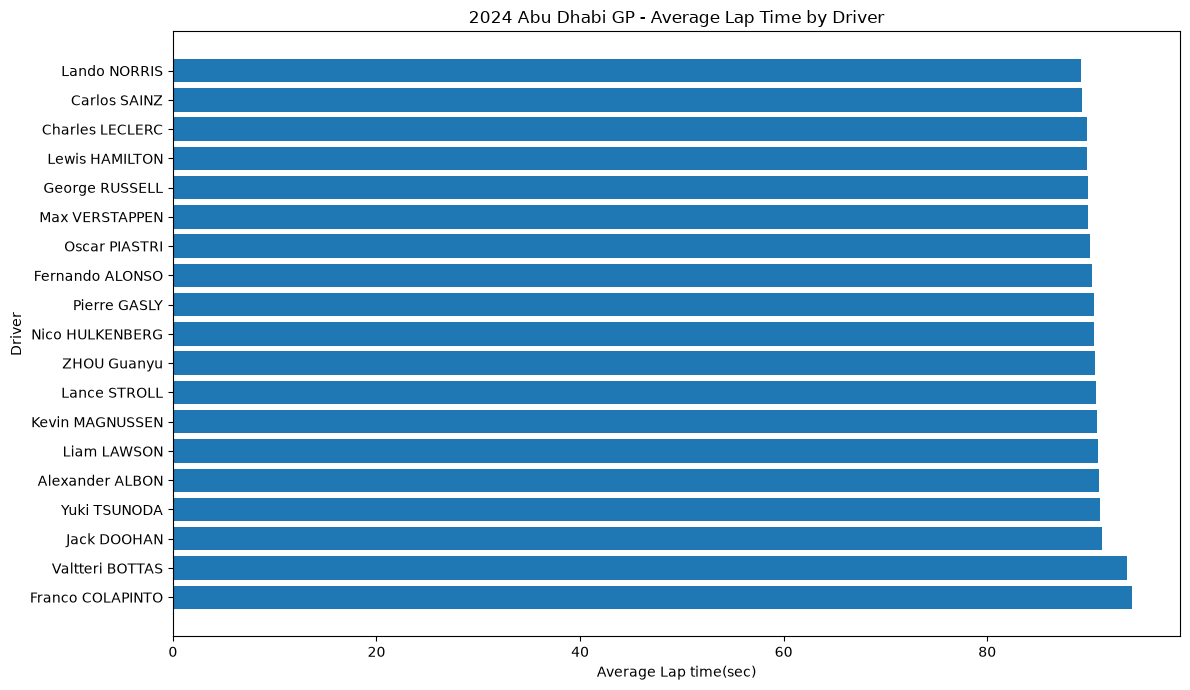

In [27]:
plt.figure(figsize=(12,7))

plt.barh(
    driver_performance['full_name'],
    driver_performance['mean']
)

plt.xlabel("Average Lap time(sec)")
plt.ylabel("Driver")
plt.title("2024 Abu Dhabi GP - Average Lap Time by Driver")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

- **Norris** with the ***lowest Average Lap time*** but not the lowest standard deviation , which shows that **speed is not equal to consistency**

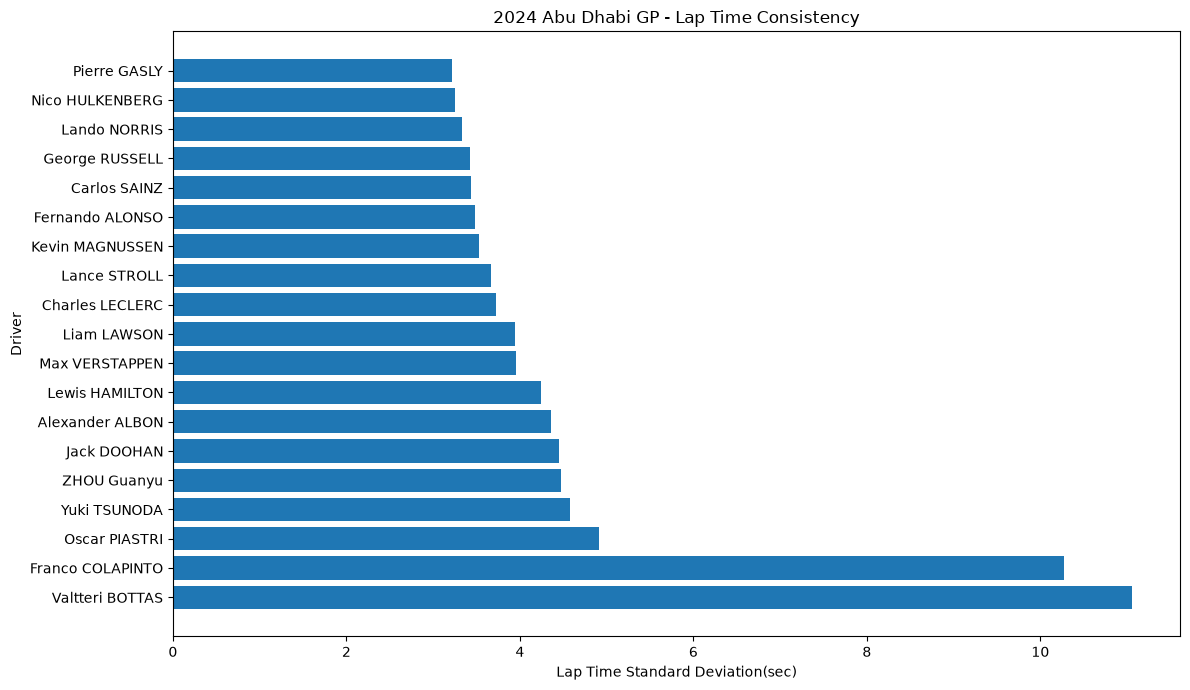

In [28]:
import matplotlib.pyplot as plt

consistency = driver_performance.sort_values(
    by="std"
)

plt.figure(figsize=(12,7))

plt.barh(
    consistency['full_name'],
    consistency['std']
)

plt.title("2024 Abu Dhabi GP - Lap Time Consistency")
plt.xlabel("Lap Time Standard Deviation(sec)")
plt.ylabel("Driver")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [29]:
print(
    consistency[
        ['full_name', 'team_name', 'mean', 'std', 'count']
    ].head(10).round(3)
)

          full_name     team_name    mean    std  count
8      Pierre GASLY        Alpine  90.465  3.216     57
9   Nico HULKENBERG  Haas F1 Team  90.521  3.257     57
0      Lando NORRIS       McLaren  89.232  3.332     57
4    George RUSSELL      Mercedes  89.868  3.430     57
1      Carlos SAINZ       Ferrari  89.335  3.439     57
7   Fernando ALONSO  Aston Martin  90.261  3.485     56
12  Kevin MAGNUSSEN  Haas F1 Team  90.755  3.524     53
11     Lance STROLL  Aston Martin  90.644  3.671     55
2   Charles LECLERC       Ferrari  89.771  3.719     57
13      Liam LAWSON            RB  90.903  3.948     52


- **Lower Standard Deviation** = More Consistent Lap times
- **Higher Standard Deviation** = Less Consistent Lap Times

***Engineering Observation:***

- Fatest driver is not the most consistent driver

*Lando Norris:*
Average = 89.232 s
Std     = 3.332 s

*Gasly:*
Average = 90.465 s
Std     = 3.216 s

Norris is **faster** but Gasly is more **consistent**

Moreover, std is also affected by things such as:
- pit-related laps
- traffic
- safety-car periods
- tyre condition
- fuel load
- race circumstances
- laps missing from the datasetstd is affected by things such as:
- pit-related laps
- traffic
- safety-car periods
- tyre condition
- fuel load
- race circumstances
- laps missing from the dataset

###Pace vs Consistency

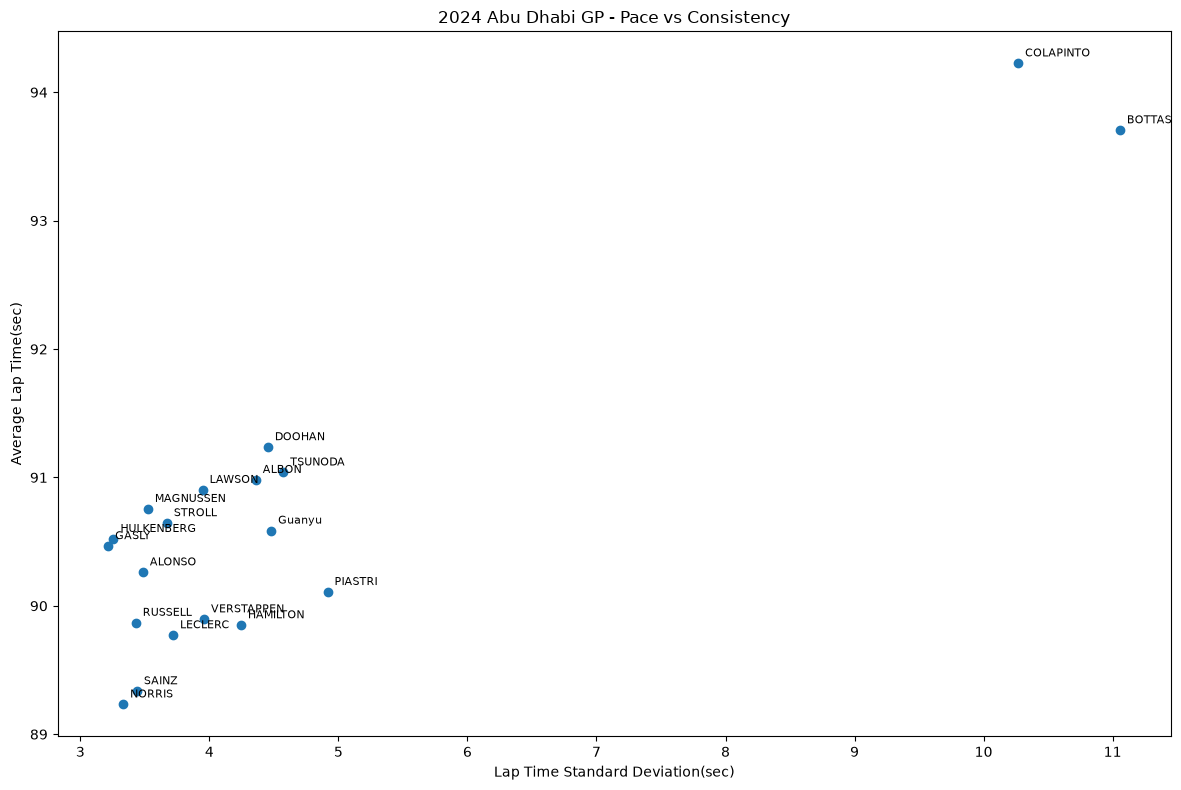

In [30]:
plt.figure(figsize=(12, 8))

plt.scatter(
    driver_performance['std'],
    driver_performance['mean']
)

# for adjusting labels use split function with row["full_name"]
for _, row in driver_performance.iterrows():
    plt.annotate(
        row['full_name'].split()[-1],
        (row['std'], row['mean']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=8
    )

plt.title("2024 Abu Dhabi GP - Pace vs Consistency")
plt.xlabel("Lap Time Standard Deviation(sec)")
plt.ylabel("Average Lap Time(sec)")

plt.tight_layout()
plt.show()

- Actually, because lower is better for both axes, the ideal driver is toward the **bottom-left**.

In [31]:
%pip install adjustText

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


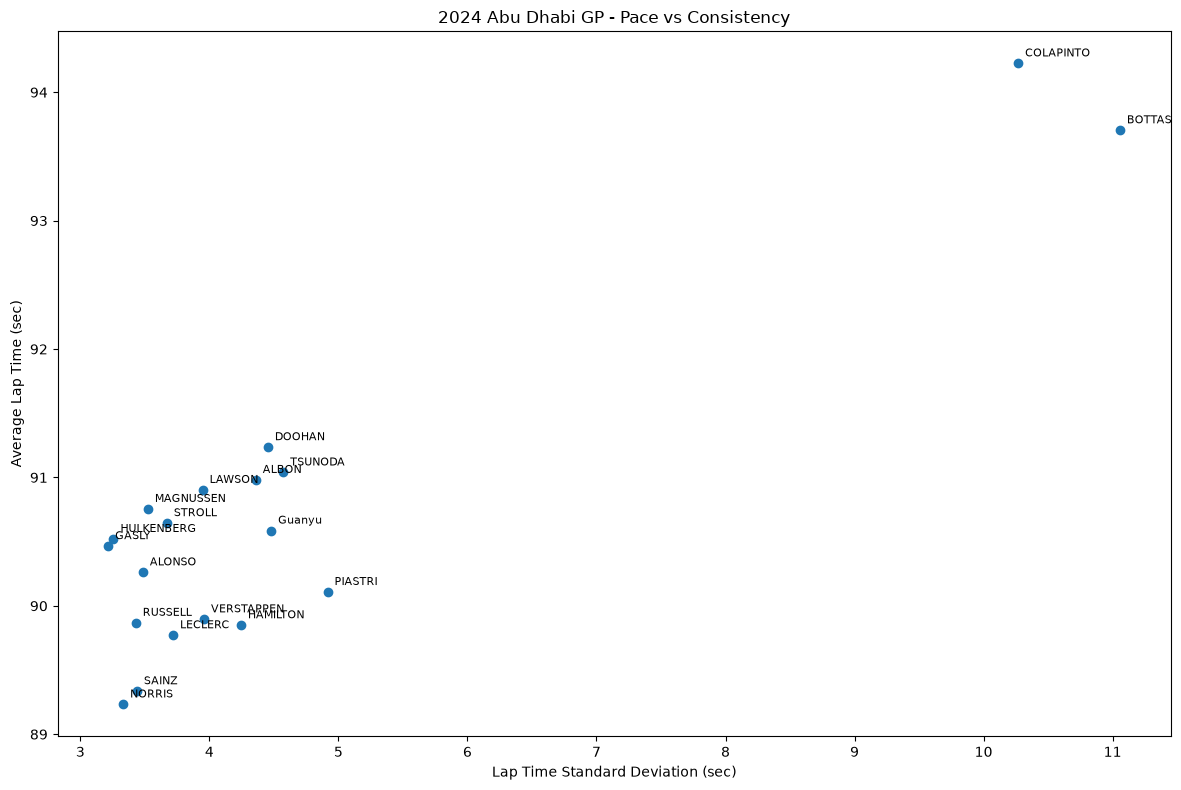

In [32]:
# For more adjusstment use adjust_text from adjustText 

from adjustText import adjust_text

plt.figure(figsize=(12, 8))

plt.scatter(
    driver_performance['std'],
    driver_performance['mean']
)

texts = []

for _, row in driver_performance.iterrows():
    plt.annotate(
        row['full_name'].split()[-1],
        (row['std'], row['mean']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=8
    )

adjust_text(texts)

plt.xlabel('Lap Time Standard Deviation (sec)')
plt.ylabel('Average Lap Time (sec)')
plt.title('2024 Abu Dhabi GP - Pace vs Consistency')

plt.tight_layout()
plt.show()

- The axes are:
- **X-axis = standard deviation** → lower means more consistent
- **Y-axis = average lap time** → lower means faster
So the best region is bottom-left: fast and consistent.

- Lando Norris → ***89.232 s average***, 3.332 s std → **very fast** and reasonably consistent
- Carlos Sainz → 89.335 s, 3.439 s → very fast, slightly less consistent
- George Russell → 89.868 s, 3.430 s → fast and consistent
- Pierre Gasly → 90.465 s, **3.216 s** → ***most consistent***, but slower
- Nico Hülkenberg → 90.521 s, 3.257 s → also highly consistent
- #77 and #43 are far to the right and high up → much greater lap-time variation and slower average pace.


From the graph:
- Lando Norris has the strongest combination of low average lap time and relatively low variation.
- Carlos Sainz is also very fast with reasonably controlled variation.
- George Russell sits in a similar fast/consistent region.
- Pierre Gasly has the lowest standard deviation, but his average lap time is slower.
- Therefore, consistency alone doesn't determine race pace.

### V1 First Finding

**Race performance should be evaluated using multiple dimensions rather than a single metric.**



# Sector Performance

In [35]:
sector_data = race_data[
    [
        'driver_number',
        'lap_number',
        'duration_sector_1',
        'duration_sector_2',
        'duration_sector_3'
    ]
]

print(sector_data.info())

<class 'pandas.core.frame.DataFrame'>
Index: 1005 entries, 0 to 1036
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   driver_number      1005 non-null   int64  
 1   lap_number         1005 non-null   int64  
 2   duration_sector_1  1001 non-null   float64
 3   duration_sector_2  1005 non-null   float64
 4   duration_sector_3  1005 non-null   float64
dtypes: float64(3), int64(2)
memory usage: 47.1 KB
None


In [37]:
sector_data[
    ['duration_sector_1',
    'duration_sector_2',
    'duration_sector_3']
].describe()

,duration_sector_1,duration_sector_2,duration_sector_3
count,1001.000000,1005.000000,1005.000000
mean,18.172751,38.898285,33.437492
std,1.206313,2.283937,2.137799
min,17.257000,37.109000,31.271000
25%,17.832000,38.243000,32.706000
50%,17.979000,38.522000,33.136000
75%,18.098000,38.775000,33.531000
max,30.241000,59.734000,65.560000


In [38]:
sector_performance = race_data.groupby(
    'driver_number'
)[
    [
    'duration_sector_1',
    'duration_sector_2',
    'duration_sector_3'
    ]
].mean()

print(sector_performance.round(3))

               duration_sector_1  duration_sector_2  duration_sector_3
driver_number                                                         
1                         18.069             38.731             33.095
4                         18.076             38.481             32.675
10                        18.153             38.942             33.371
14                        18.093             38.876             33.292
16                        18.131             38.536             33.104
18                        18.180             38.838             33.639
20                        18.258             38.750             33.747
22                        18.249             39.132             33.659
23                        18.281             38.984             33.721
24                        18.161             39.023             33.402
27                        18.253             38.774             33.493
30                        18.239             39.121             33.543
43    

In [58]:
sector_performance = race_data.groupby(
    'driver_number'
)[
    [
    'duration_sector_1',
    'duration_sector_2',
    'duration_sector_3'
    ]
].mean()

sector_performance = sector_performance.merge(
    drivers[['driver_number', 'full_name', 'team_name']].drop_duplicates(subset=["driver_number"]),
    on='driver_number',
    how='left'
)

print(
    sector_performance[
        ['full_name', 'team_name', 'duration_sector_1', 'duration_sector_2', 'duration_sector_3']
    ].round(3)
)


           full_name        team_name  duration_sector_1  duration_sector_2  \
0     Max VERSTAPPEN  Red Bull Racing             18.069             38.731   
1       Lando NORRIS          McLaren             18.076             38.481   
2       Pierre GASLY           Alpine             18.153             38.942   
3    Fernando ALONSO     Aston Martin             18.093             38.876   
4    Charles LECLERC          Ferrari             18.131             38.536   
5       Lance STROLL     Aston Martin             18.180             38.838   
6    Kevin MAGNUSSEN     Haas F1 Team             18.258             38.750   
7       Yuki TSUNODA               RB             18.249             39.132   
8    Alexander ALBON         Williams             18.281             38.984   
9        ZHOU Guanyu      Kick Sauber             18.161             39.023   
10   Nico HULKENBERG     Haas F1 Team             18.253             38.774   
11       Liam LAWSON               RB             18

### Sector-wise Sorting fastest

In [62]:
fastest_s1 = sector_performance.sort_values(
    by="duration_sector_1"
)

fastest_s2 = sector_performance.sort_values(
    by="duration_sector_2"
)

fastest_s3 = sector_performance.sort_values(
    by="duration_sector_3"
)

print(
    fastest_s1[
        ['driver_number','full_name', 'team_name', 'duration_sector_1']
    ].round(3)
)

print(
    fastest_s2[
        ['driver_number','full_name', 'team_name', 'duration_sector_2']
    ].round(3)
)

print(
    fastest_s3[
        ['driver_number','full_name', 'team_name', 'duration_sector_3']
    ].round(3)
)

    driver_number         full_name        team_name  duration_sector_1
16             63    George RUSSELL         Mercedes             17.999
13             44    Lewis HAMILTON         Mercedes             18.002
0               1    Max VERSTAPPEN  Red Bull Racing             18.069
1               4      Lando NORRIS          McLaren             18.076
3              14   Fernando ALONSO     Aston Martin             18.093
14             55      Carlos SAINZ          Ferrari             18.104
4              16   Charles LECLERC          Ferrari             18.131
2              10      Pierre GASLY           Alpine             18.153
9              24       ZHOU Guanyu      Kick Sauber             18.161
15             61       Jack DOOHAN           Alpine             18.167
18             81     Oscar PIASTRI          McLaren             18.176
5              18      Lance STROLL     Aston Martin             18.180
11             30       Liam LAWSON               RB            

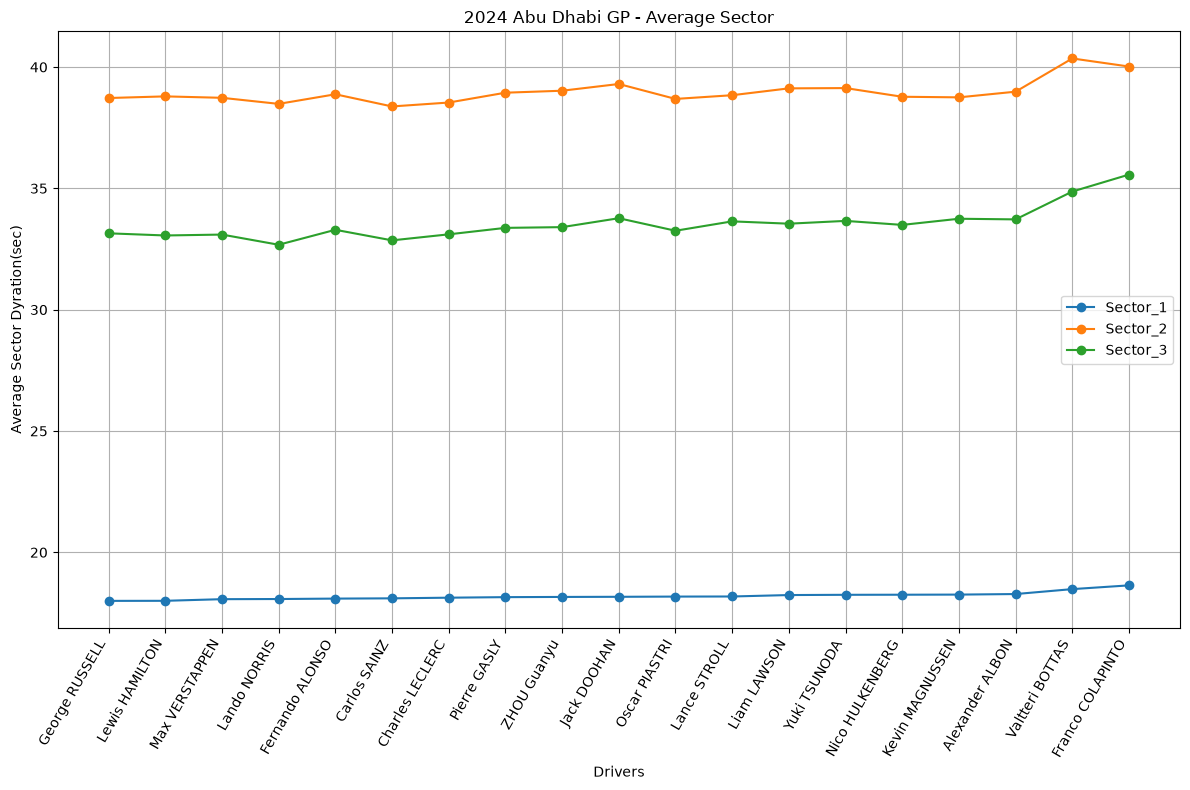

In [64]:
plt.figure(figsize=(12,8))

sector_plot = sector_performance.sort_values(
    by="duration_sector_1"
)

plt.plot(
    sector_plot["full_name"],
    sector_plot["duration_sector_1"],
    marker="o",
    label="Sector_1"
)

plt.plot(
    sector_plot["full_name"],
    sector_plot["duration_sector_2"],
    marker="o",
    label="Sector_2"
)

plt.plot(
    sector_plot["full_name"],
    sector_plot["duration_sector_3"],
    marker="o",
    label="Sector_3"
)

plt.xlabel("Drivers")
plt.ylabel("Average Sector Dyration(sec)")
plt.title("2024 Abu Dhabi GP - Average Sector")
plt.xticks(rotation=60, ha='right')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()



### Sector Performance relative to fastest driver

In [68]:
sector_gap = sector_performance.copy()

sector_gap["s1_gap"] = sector_gap["duration_sector_1"] - sector_gap["duration_sector_1"].min()
sector_gap["s2_gap"] = sector_gap["duration_sector_2"] - sector_gap["duration_sector_2"].min()
sector_gap["s3_gap"] = sector_gap["duration_sector_3"] - sector_gap["duration_sector_3"].min()

print(
    sector_gap[["full_name", "team_name", "s1_gap", "s2_gap", "s3_gap"]].sort_values("s1_gap").round(3)
)


           full_name        team_name  s1_gap  s2_gap  s3_gap
16    George RUSSELL         Mercedes   0.000   0.347   0.471
13    Lewis HAMILTON         Mercedes   0.003   0.415   0.382
0     Max VERSTAPPEN  Red Bull Racing   0.070   0.356   0.419
1       Lando NORRIS          McLaren   0.077   0.106   0.000
3    Fernando ALONSO     Aston Martin   0.094   0.501   0.616
14      Carlos SAINZ          Ferrari   0.105   0.000   0.181
4    Charles LECLERC          Ferrari   0.132   0.161   0.429
2       Pierre GASLY           Alpine   0.154   0.566   0.696
9        ZHOU Guanyu      Kick Sauber   0.162   0.648   0.726
15       Jack DOOHAN           Alpine   0.168   0.925   1.093
18     Oscar PIASTRI          McLaren   0.177   0.310   0.577
5       Lance STROLL     Aston Martin   0.181   0.463   0.964
11       Liam LAWSON               RB   0.240   0.745   0.868
7       Yuki TSUNODA               RB   0.250   0.757   0.983
10   Nico HULKENBERG     Haas F1 Team   0.254   0.399   0.818
6    Kev

### Driver sector-strength profile

In [69]:
top_drivers = sector_gap[
    sector_gap["full_name"].isin([
        'Lando NORRIS',
        'Carlos SAINZ',
        'George RUSSELL',
        'Charles LECLERC',
        'Max VERSTAPPEN'
    ])
]


print(
    top_drivers[
        ["full_name", "team_name", "s1_gap", "s2_gap", "s3_gap"]
    ]
)

          full_name        team_name    s1_gap    s2_gap    s3_gap
0    Max VERSTAPPEN  Red Bull Racing  0.070368  0.355719  0.419474
1      Lando NORRIS          McLaren  0.076561  0.105930  0.000000
4   Charles LECLERC          Ferrari  0.131684  0.160930  0.428982
14     Carlos SAINZ          Ferrari  0.104632  0.000000  0.180754
16   George RUSSELL         Mercedes  0.000000  0.347439  0.470930


**Norris** has the strongest S3 performance.

He's only:
0.000 s from the fastest S3 average.
And he's also only 0.106 s away from the fastest S2.
That helps explain why Norris had the best overall average lap time in our earlier analysis.

**Sainz** has a very different profile.

He is:
- 0.105 s behind in S1
- fastest in S2
- 0.181 s behind in S3
So Sainz's strongest relative advantage is clearly Sector 2.

**Russell** is almost the opposite.

He is:
- fastest in S1
- 0.347 s behind in S2
- 0.471 s behind in S3
So despite being the S1 benchmark, he gives up considerably more time in the later sectors.

**Verstappen** is interesting
Verstappen is very close to the S1 benchmark:

0.070 s
but loses more time in S2 and S3.

This shows why sector analysis adds information that overall lap time hides.

Two drivers can have similar overall pace while getting there through very different sector profiles.
One important limitation
Don't interpret these gaps as saying why a driver is faster.

For example, we cannot yet say:
"Norris is faster in S3 because of better aerodynamic efficiency."

We don't have enough data for that conclusion yet.

At this stage we can only say:
**Norris demonstrated the strongest average Sector 3 performance relative to the field in this race.**

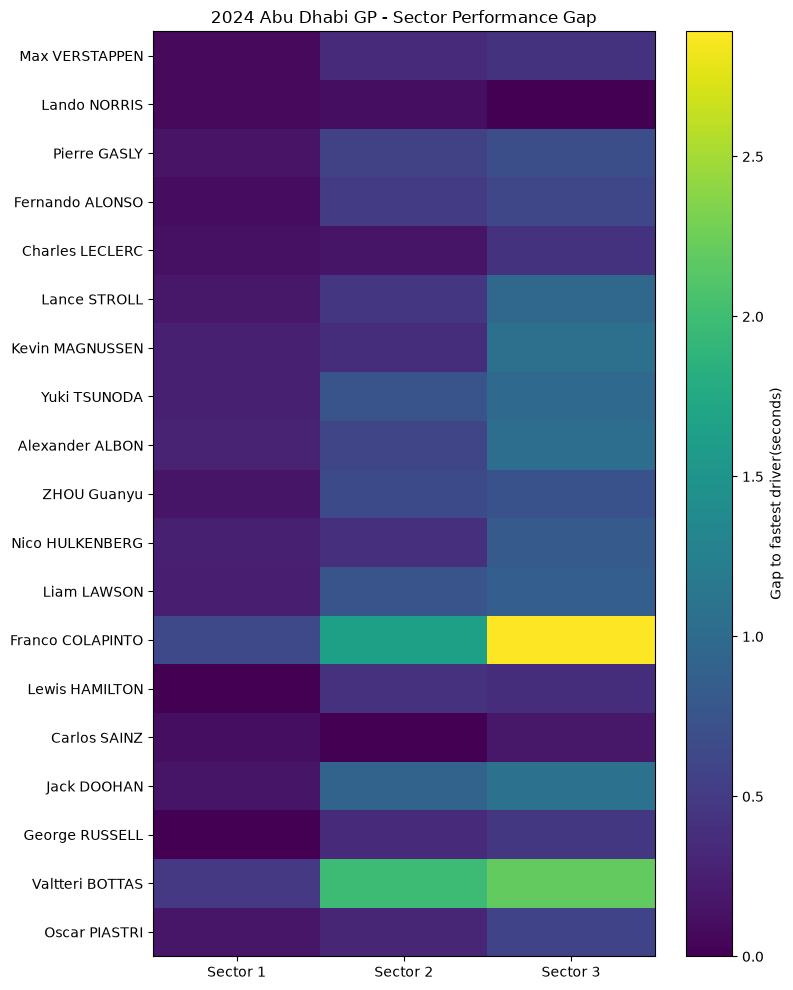

In [71]:
heatmap_data = sector_gap.set_index("full_name")[["s1_gap", "s2_gap", "s3_gap"]]

plt.figure(figsize=(8,10))

plt.imshow(heatmap_data,aspect="auto")

plt.xticks(range(3), ["Sector 1", "Sector 2", "Sector 3"])

plt.yticks(range(len(heatmap_data)), heatmap_data.index)

plt.colorbar(label="Gap to fastest driver(seconds)")

plt.title("2024 Abu Dhabi GP - Sector Performance Gap")

plt.tight_layout()
plt.show()

**Three things stand out**
1. ***Norris*** has a very strong overall sector profile

His row stays dark across all three sectors, especially S3.

That's consistent with what we found earlier:
- Best overall average lap time
- Fastest average S3
- Very small S2 gap
- Small S1 gap
So his pace isn't coming from one isolated sector — he is competitive throughout the lap.

2. ***Sainz*** has a particularly strong S2

His S2 cell is essentially the benchmark:
0.000 s gap

He also has a relatively small S3 gap, while losing slightly more in S1.

3. ***Russell*** has a very strong S1

His S1 is:
0.000 s gap

But his S2 and S3 gaps are larger. This gives us a clear example of how a driver can be excellent in one part of the circuit without necessarily having the best overall lap.

**The biggest outlier**
Franco Colapinto has a noticeably larger S3 gap, and his S2 gap is also substantial.

Valtteri Bottas also shows relatively large gaps in S2 and S3.

These are exactly the kinds of patterns worth investigating later rather than simply saying "they were slower."

**One correction to our interpretation**
The heatmap's colours are not directly comparable across columns in the way a normal absolute colour scale would suggest, because the gaps were calculated separately for each sector but then plotted on one colour scale.

### Tyre Strategy

In [73]:
url = "https://api.openf1.org/v1/stints"

params = {
    "session_key" : session_key
}

response = requests.get(
    url,
    params = params,
    timeout = 30
)

response.raise_for_status()

stints = pd.DataFrame(response.json())

print("Total Stints records: ",len(stints))
print(stints.columns.tolist())
print(stints.head())

Total Stints records:  48
['meeting_key', 'session_key', 'stint_number', 'driver_number', 'lap_start', 'lap_end', 'compound', 'tyre_age_at_start']
   meeting_key  session_key  stint_number  driver_number  lap_start  lap_end  \
0         1252         9662             1             55          1       25   
1         1252         9662             1             30          1       23   
2         1252         9662             1             10          1       14   
3         1252         9662             1             81          1        4   
4         1252         9662             1             61          1       22   

  compound  tyre_age_at_start  
0   MEDIUM                  0  
1   MEDIUM                  0  
2   MEDIUM                  0  
3   MEDIUM                  0  
4   MEDIUM                  0  


###How did lap time change as a tyre became older?

In [ ]:
stint_summary = stints.copy()

stint_summary["stint_length"] = (
    stint_summary['lap_end'] - stint_summary["lap_start"] + 1
)

print(
    stint_summary[
        [
        "driver_number",
        "stint_number",
        "lap_start",
        "lap_end",
        "stint_length",
        "compound",
        "tyre_age_at_start"
        ]
    ].sort_values(
        ["driver_number", "stint_number"]
    )
)

    driver_number  stint_number  lap_start  lap_end  stint_length compound  \
8               1             1          1       29            29   MEDIUM   
38              1             2         30       58            29     HARD   
15              4             1          1       26            26   MEDIUM   
36              4             2         27       58            32     HARD   
2              10             1          1       14            14   MEDIUM   
29             10             2         15       58            44     HARD   
6              11             1          1        1             1   MEDIUM   
18             14             1          1       13            13   MEDIUM   
28             14             2         14       37            24     HARD   
45             14             3         38       58            21     HARD   
5              16             1          1       20            20   MEDIUM   
30             16             2         21       58            3

In [86]:
lap_stints = []

for _, stint in stints.iterrows():

    driver_laps = race_data[
        (race_data["driver_number"] == stint["driver_number"]) &
        (race_data["lap_number"] >= stint["lap_start"]) &
        (race_data["lap_number"] <= stint["lap_end"])
    ].copy()

    driver_laps["stint_number"] = stint["stint_number"]
    driver_laps["compound"] = stint["compound"]
    driver_laps["tyre_age_at_start"] = stint["tyre_age_at_start"]
    driver_laps["lap_start"] = stint["lap_start"]

    lap_stints.append(driver_laps)

race_tyre_data = pd.concat(lap_stints, ignore_index=True)

print("Total lap-tyre record: ", len(race_tyre_data))

print(
    race_tyre_data[
        ["driver_number", "lap_number", "lap_duration", "stint_number", "compound", "tyre_age_at_start"]
    ].head(20)
)


Total lap-tyre record:  1005
    driver_number  lap_number  lap_duration  stint_number compound  \
0              55           1        93.513             1   MEDIUM   
1              55           2       109.770             1   MEDIUM   
2              55           3       102.795             1   MEDIUM   
3              55           4        88.995             1   MEDIUM   
4              55           5        89.250             1   MEDIUM   
5              55           6        89.253             1   MEDIUM   
6              55           7        89.063             1   MEDIUM   
7              55           8        89.202             1   MEDIUM   
8              55           9        89.187             1   MEDIUM   
9              55          10        89.320             1   MEDIUM   
10             55          11        89.246             1   MEDIUM   
11             55          12        89.150             1   MEDIUM   
12             55          13        89.192             1   M

In [90]:


race_tyre_data["tyre_age"] = (
    race_tyre_data["tyre_age_at_start"] + 
    (race_tyre_data["lap_number"] - race_tyre_data["lap_start"])
)

print(
    race_tyre_data[
        ["driver_number", "lap_number", "lap_duration", "stint_number", "compound", "tyre_age"]
    ].tail(20)
)

      driver_number  lap_number  lap_duration  stint_number compound  tyre_age
985              14          57        88.937             3     HARD        20
986              14          58        88.621             3     HARD        21
987              24          41        88.255             3     HARD         1
988              24          42        88.303             3     HARD         2
989              24          43        88.690             3     HARD         3
990              24          44        88.678             3     HARD         4
991              24          45        88.689             3     HARD         5
992              24          46        88.862             3     HARD         6
993              24          47        88.682             3     HARD         7
994              24          48        88.619             3     HARD         8
995              24          49        89.096             3     HARD         9
996              24          50        90.162       

###How many laps did each tyre compound contribute to the race?

In [94]:
race_tyre_data.groupby(race_tyre_data["compound"])["lap_number"].count()

# print(
#     race_tyre_data[
#         ["driver_number", "lap_number", "compound"]
#     ]
# )

compound
HARD      664
MEDIUM    316
SOFT       25
Name: lap_number, dtype: int64

In [97]:
race_tyre_data.groupby(race_tyre_data["compound"])["tyre_age"].max()

compound
HARD      44
MEDIUM    28
SOFT      24
Name: tyre_age, dtype: int64

In [99]:
print(
    race_tyre_data.groupby(
        ["driver_number","compound", "stint_number"]
    )["lap_number"].count()
)

driver_number  compound  stint_number
1              HARD      2               28
               MEDIUM    1               29
4              HARD      2               31
               MEDIUM    1               26
10             HARD      2               43
               MEDIUM    1               14
14             HARD      2               23
                         3               20
               MEDIUM    1               13
16             HARD      2               37
               MEDIUM    1               20
18             HARD      2               20
                         3               24
               MEDIUM    1               11
20             HARD      2               16
               MEDIUM    1               12
               SOFT      4               24
                         5                1
22             HARD      2               34
               MEDIUM    1               22
23             HARD      2               44
               MEDIUM    1            